In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.ensemble import ExtraTreesClassifier, RandomForestClassifier
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, f1_score

from src.importancias import graficar_importancia_agrupada

X_train = pd.read_csv("../data/X_train_pycaret.csv")
X_test = pd.read_csv("../data/X_test_pycaret.csv")
y_train = pd.read_csv("../data/y_train_pycaret.csv").squeeze()
y_test = pd.read_csv("../data/y_test_pycaret.csv").squeeze()

### 1. alinear train y test
Se alinean las columnas de X_train y X_test (en caso que alguna columna no quedó presente en ambos conjuntos) y se verifica que no queden valores nulos residuales, rellenándolos con la mediana calculada sobre el set de entrenamiento.

In [2]:
# Celda 2 (opcional): Alinear columnas y manejar posibles nulos residuales
X_train, X_test = X_train.align(X_test, join='left', axis=1, fill_value=0)

num_cols = X_train.select_dtypes(include='number').columns
medianas_train = X_train[num_cols].median()
X_train[num_cols] = X_train[num_cols].fillna(medianas_train)
X_test[num_cols] = X_test[num_cols].fillna(medianas_train)

### 2. entreno con hiperparametros
Se entrenan manualmente GradientBoostingClassifier y RandomForestClassifier con hiperparámetros por defecto comparando su F1-score (macro) tanto en entrenamiento y prueba, revisando su matriz de confusión.
 Esto permite validar si los resultados obtenidos por PyCaret se replican aparte de detectar señales tempranas de sobreajuste.

In [3]:
modelos = {
    "Gradient Boosting": GradientBoostingClassifier(random_state=454),
    "Random Forest": RandomForestClassifier(random_state=454, n_jobs=-1)
}

# El resto del bucle se mantiene igual, ya que usa '{nombre}' de forma automática:
for nombre, modelo in modelos.items():
    print(f"\n========================================")
    print(f"Evaluando modelo: {nombre}")
    print(f"========================================")

    modelo.fit(X_train, y_train)

    y_pred_train = modelo.predict(X_train)
    y_pred_test = modelo.predict(X_test)

    f1_train = f1_score(y_train, y_pred_train, average='macro')
    f1_test = f1_score(y_test, y_pred_test, average='macro')

    print(f"F1-Score (Train): {f1_train:.4f}")
    print(f"F1-Score (Test):  {f1_test:.4f}")

    print(classification_report(y_test, y_pred_test))

    plt.figure(figsize=(6, 4))
    sns.heatmap(confusion_matrix(y_test, y_pred_test), annot=True, fmt='d', cmap='Blues', cbar=False)
    plt.title(f'Matriz de Confusión - {nombre} (Test)') # <--- Se pone automáticamente
    plt.xlabel('Predicción')
    plt.ylabel('Valor Real')
    plt.show()


Evaluando modelo: Gradient Boosting
F1-Score (Train): 0.8634
F1-Score (Test):  0.8465
              precision    recall  f1-score   support

           0       0.89      0.93      0.91      4300
           1       0.82      0.75      0.78      1893

    accuracy                           0.87      6193
   macro avg       0.86      0.84      0.85      6193
weighted avg       0.87      0.87      0.87      6193



<Figure size 600x400 with 1 Axes>


Evaluando modelo: Random Forest
F1-Score (Train): 1.0000
F1-Score (Test):  0.8461
              precision    recall  f1-score   support

           0       0.89      0.93      0.91      4300
           1       0.82      0.75      0.78      1893

    accuracy                           0.87      6193
   macro avg       0.86      0.84      0.85      6193
weighted avg       0.87      0.87      0.87      6193



<Figure size 600x400 with 1 Axes>

### 3. Busqueda automatica
Se optimizan los hiperparámetros en ambos modelos mediante búsqueda automática, en caso de Random Forest con RandomizedSearchCV (que es búsqueda aleatoria sobre n_estimators, max_depth y min_samples_leaf) y Gradient Boosting con BayesSearchCV (que es optimización bayesiana osea encontrar el minimo o maximo de funciones, sobre n_estimators, learning_rate y max_depth)
 ambos validados con StratifiedKFold para preservar la proporción de clases en cada partición y usando F1-macro como métrica de selección.

In [4]:
from src.optimizacion import optimizar_random_forest

mejor_rf, mejores_params_rf = optimizar_random_forest(X_train, y_train, X_test, y_test)

=== Modelo: Random Forest Classifier (Búsqueda Aleatoria (RandomizedSearchCV)) ===
Tiempo de ejecución: 35.5 s

Hiperparámetros ajustados y qué hacen:
  - n_estimators: Número de árboles del bosque: más árboles suelen estabilizar la predicción, pero aumentan el tiempo de cómputo.
  - max_depth: Profundidad máxima de cada árbol: limita qué tanto se ramifica para evitar que memorice el entrenamiento (sobreajuste).
  - min_samples_leaf: Mínimo de muestras requeridas en una hoja final: suaviza las decisiones y evita hojas con muy pocos datos.

Mejores hiperparámetros encontrados:
  - max_depth = 13
  - min_samples_leaf = 3
  - n_estimators = 191

Métricas del mejor modelo (Test):
  - F1-Score (macro): 0.8456  (Train: 0.9147)
  - Recall (macro):   0.8349
  - Accuracy:         0.8732


In [5]:
from src.optimizacion import optimizar_gradient_boosting

mejor_gb, mejores_params_gb = optimizar_gradient_boosting(X_train, y_train, X_test, y_test)

=== Modelo: Gradient Boosting Classifier (Optimización Bayesiana (BayesSearchCV)) ===
Tiempo de ejecución: 164.3 s

Hiperparámetros ajustados y qué hacen:
  - n_estimators: Número de etapas/árboles secuenciales: cada nuevo árbol corrige errores de los anteriores.
  - learning_rate: Tasa de aprendizaje: controla cuánto aporta cada árbol nuevo; valores menores requieren más árboles pero generalizan mejor.
  - max_depth: Profundidad máxima de cada árbol débil: controla la complejidad de las interacciones entre variables.

Mejores hiperparámetros encontrados:
  - learning_rate = 0.06660487135275893
  - max_depth = 4
  - n_estimators = 150

Métricas del mejor modelo (Test):
  - F1-Score (macro): 0.8486  (Train: 0.8731)
  - Recall (macro):   0.8399
  - Accuracy:         0.8749


### 4. comparacion
ahora se comparan de forma visual los F1-scores de los entrenamientos y pruebas antes y después de la optimización para diagnosticar en que tanto se redujo el sobreajuste.
Un modelo con F1 de entrenamiento mucho más alto que el de prueba es señal de que esta memorizando los datos en vez de generalizarlos, tras la optimización se espera que ambos valores sean ceranos.

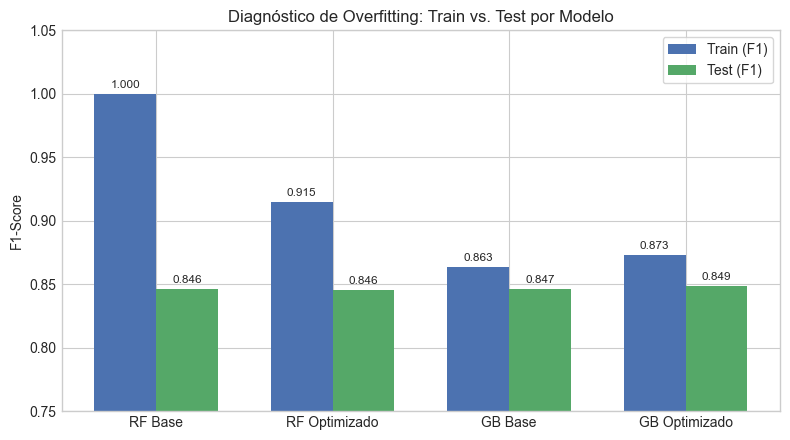

In [6]:
import matplotlib.pyplot as plt
import numpy as np

# Reemplaza estos valores con las métricas exactas de tu diccionario/evaluación
modelos = [
    "RF Base",
    "RF Optimizado",
    "GB Base",
    "GB Optimizado",
]
f1_train = [1.0000, 0.9147, 0.8634, 0.8731]
f1_test = [0.8461, 0.8456, 0.8465, 0.8486]

x = np.arange(len(modelos))
width = 0.35

plt.style.use("seaborn-v0_8-whitegrid")
fig, ax = plt.subplots(figsize=(8, 4.5))

rects1 = ax.bar(
    x - width / 2, f1_train, width, label="Train (F1)", color="#4C72B0"
)
rects2 = ax.bar(
    x + width / 2, f1_test, width, label="Test (F1)", color="#55A868"
)

ax.set_ylabel("F1-Score")
ax.set_title("Diagnóstico de Overfitting: Train vs. Test por Modelo")
ax.set_xticks(x)
ax.set_xticklabels(modelos)
ax.set_ylim(0.75, 1.05)
ax.legend(frameon=True)

# Etiquetas discretas sobre cada barra
for rect in rects1 + rects2:
  h = rect.get_height()
  ax.annotate(
      f"{h:.3f}",
      xy=(rect.get_x() + rect.get_width() / 2, h),
      xytext=(0, 3),
      textcoords="offset points",
      ha="center",
      va="bottom",
      fontsize=8.5,
  )

plt.tight_layout()
plt.show()

### 5. grafico de curvas
Se grafican las curvas de aprendizaje de los modelos ya optimizados, mostrando cómo evoluciona el desempeño de F1-macro en entrenamiento y en la validación cruzada a medida que aumenta el tamaño del conjunto del entrenamiento, las Curvas que convergan en un valor alto son indicativo de buena generalización mientras que curvas muy separadas muestran sobreajuste aparte de curvas bajas y juntas indican que el modelo es demasiado simple.

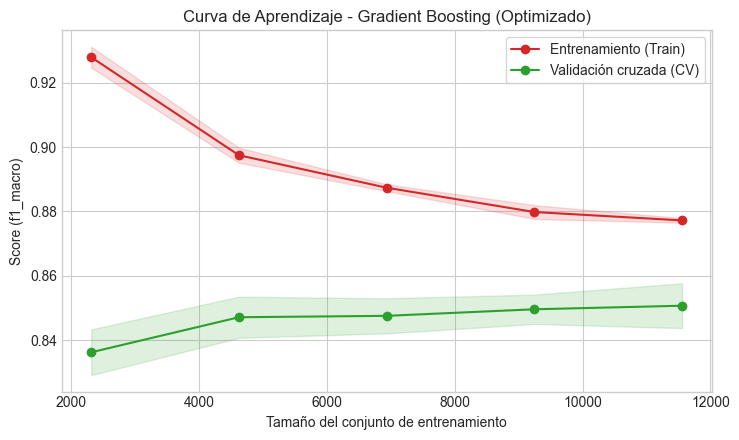

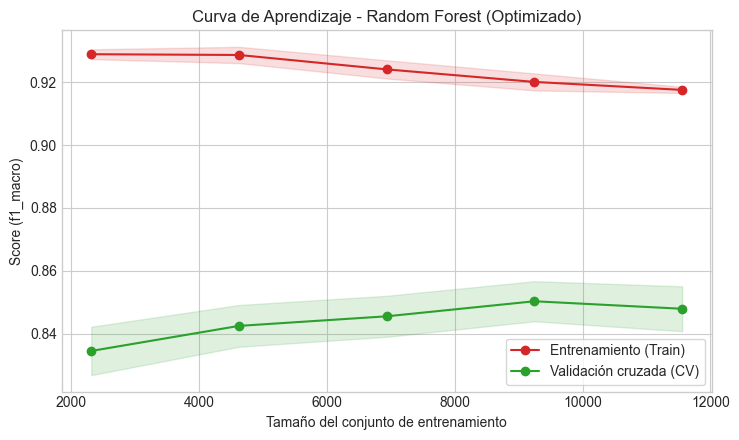

In [7]:
from src.curvas_aprendizaje import graficar_curva_aprendizaje

graficar_curva_aprendizaje(
    mejor_gb,
    X_train,
    y_train,
    titulo="Curva de Aprendizaje - Gradient Boosting (Optimizado)",
)

graficar_curva_aprendizaje(
    mejor_rf,
    X_train,
    y_train,
    titulo="Curva de Aprendizaje - Random Forest (Optimizado)",
)

### 6. importancia
Se analiza la importancia de cada variable con feature_importances_ para el modelo de Gradient Boosting optimizado para identificar qué características tienen mayor peso en las predicciones.


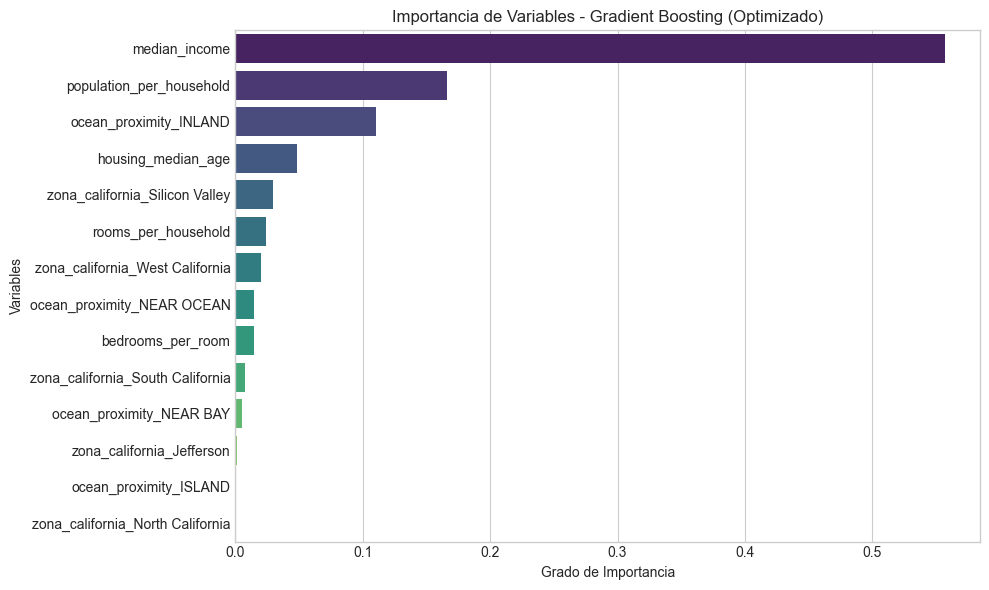

In [10]:
estimador_1 = mejor_gb
nombre_modelo_1 = "Gradient Boosting (Optimizado)"

importancias = estimador_1.feature_importances_
df_importancias = pd.DataFrame(
    {"Caracteristica": X_train.columns, "Importancia": importancias}
).sort_values(by="Importancia", ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(
    x="Importancia",
    y="Caracteristica",
    data=df_importancias,
    palette="viridis",
    hue="Caracteristica",
    legend=False,
)
plt.title(f"Importancia de Variables - {nombre_modelo_1}")
plt.xlabel("Grado de Importancia")
plt.ylabel("Variables")
plt.tight_layout()
plt.show()

### 6.1. importancia (random forest)
Se repite el mismo análisis de importancia de variables para el Random Forest optimizado para comparar si en ambos modelos coinciden en qué variables consideran ser la mas relevantes.

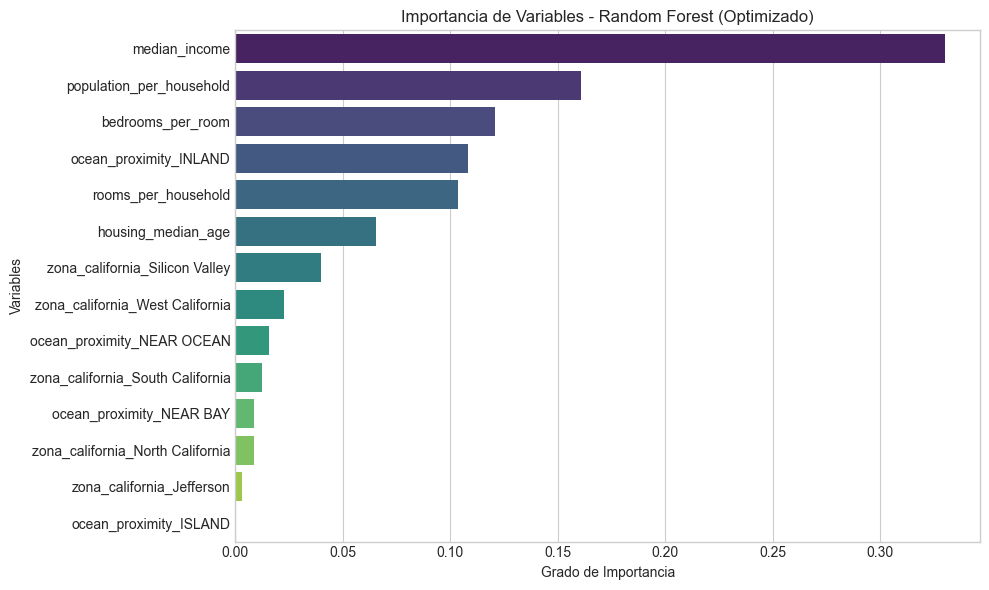

In [11]:
estimador_2 = mejor_rf
nombre_modelo_2 = "Random Forest (Optimizado)"

importancias_rf = estimador_2.feature_importances_
df_importancias_rf = pd.DataFrame(
    {"Caracteristica": X_train.columns, "Importancia": importancias_rf}
).sort_values(by="Importancia", ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(
    x="Importancia",
    y="Caracteristica",
    data=df_importancias_rf,
    palette="viridis",
    hue="Caracteristica",
    legend=False,
)
plt.title(f"Importancia de Variables - {nombre_modelo_2}")
plt.xlabel("Grado de Importancia")
plt.ylabel("Variables")
plt.tight_layout()
plt.show()

### 7. agrupacion de importancia
Dado que las variables categóricas como ocean_proximity y zona_california quedaron ya representadas por varias columnas dummy tras el One-Hot Encoding se agrupa la importancia de todas las columnas pertenecientes a una misma variable original en una sola barra.
 dando una medida más justa del peso real de la ubicación geográfica dentro del modelo en vez de fragmentarlo artificialmente entre varias columnas individuales.

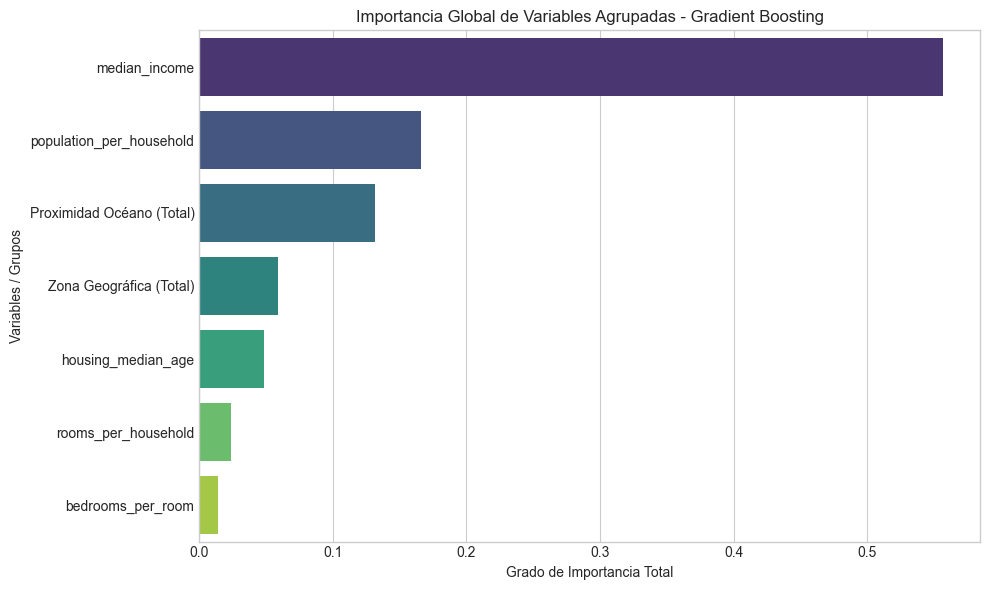

In [40]:
from src.importancias import graficar_importancia_agrupada

# Diccionario temporal con los modelos entrenados disponibles
modelos_dict = {
    "Gradient Boosting": mejor_gb,
    "Random Forest": mejor_rf,
}

# Elige el modelo ("Random Forest" o "Gradient Boosting") y ejecuta
modelo_elegido = "Gradient Boosting"
graficar_importancia_agrupada(modelos_dict, modelo_elegido, X_train.columns)

### 7.1. agrupacion de importancia (random forest)
el mismo proceso se hace con random forest

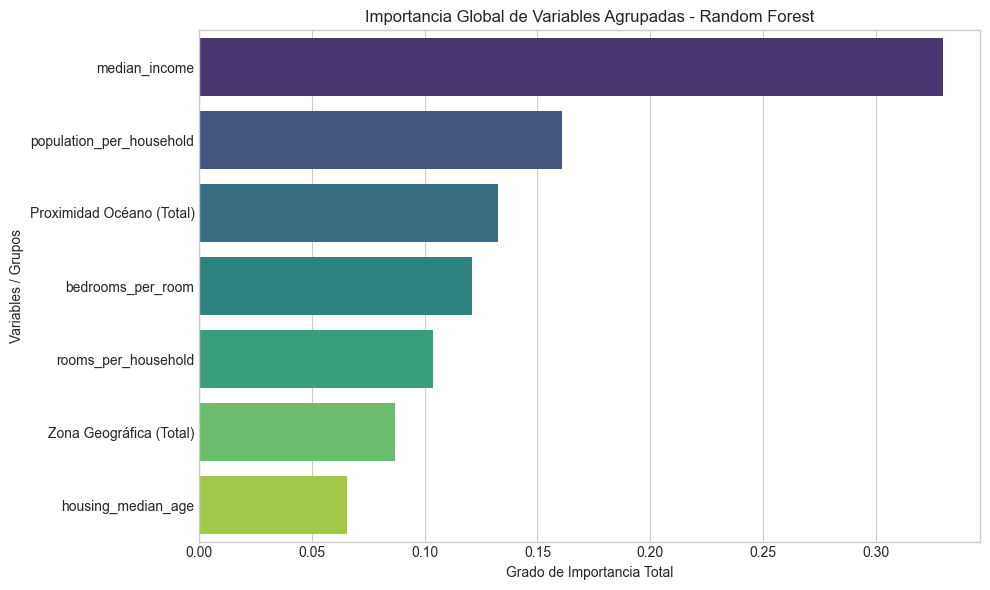

In [41]:
from src.importancias import graficar_importancia_agrupada

# Diccionario temporal con los modelos entrenados disponibles
modelos_dict = {
    "Gradient Boosting": mejor_gb,
    "Random Forest": mejor_rf,
}

# Elige el modelo ("Random Forest" o "Gradient Boosting") y ejecuta
modelo_elegido = "Random Forest"
graficar_importancia_agrupada(modelos_dict, modelo_elegido, X_train.columns)

### 8. version adicional
para Final se prueba una versión adicional del Random Forest con una regularización mucho más fuerte de max_depth y min_samples_leaf para el evaluar si es posible el reducir aún más la brecha entre el desempeño del entrenamiento y en la prueba observada en la curva de aprendizaje.


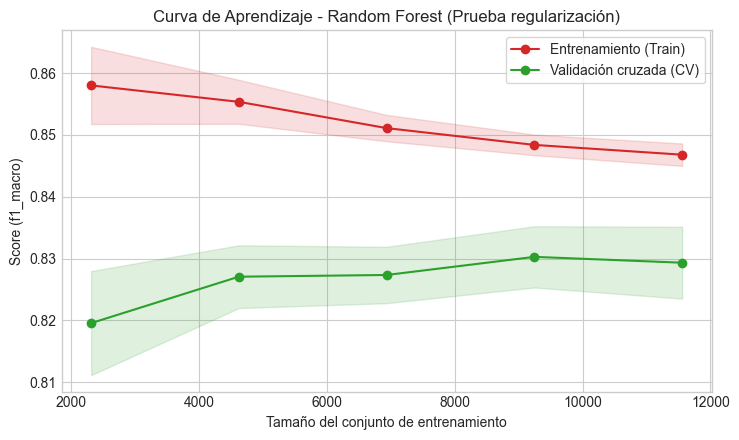

In [45]:
from sklearn.ensemble import RandomForestClassifier
from src.curvas_aprendizaje import graficar_curva_aprendizaje

# Copia base de parámetros actuales (si existen) + 1 o 2 ajustes de regularización
params_base = (
    mejor_rf.get_params() if "mejor_rf" in globals() else {"random_state": 42}
)
params_prueba = {
    **params_base,
    "max_depth": 7,  # limite de profundidad
    "min_samples_leaf": 8,  # Sube el mínimo de muestras por hoja
    "n_jobs": -1,
}

rf_menos_overfit = RandomForestClassifier(**params_prueba)

graficar_curva_aprendizaje(
    rf_menos_overfit,
    X_train,
    y_train,
    titulo="Curva de Aprendizaje - Random Forest (Prueba regularización)",
)

## 9. Conclusión

Tanto el entrenamiento manual y la optimización de los hiperparámetros confirmaron que los modelos base, especialmente Random Forest, tenían un marcado sobreajuste con el F1 de entrenamiento cercano a 1.0 frente al un F1 de prueba de ~0.85, esto se redujo notablemente al limitar la complejidad de los árboles.
 Tanto Random Forest como el Gradient Boosting optimizados alcanzaron un desempeño parecido en el conjunto de pruebas dando F1-macro cercano a 0.85 y el análisis de importancia de las variables mostró que median_income y la ubicación geográfica (tanto la zona y proximidad al océano) son los factores que más influyen en que una casa sea clasificada como de alto o bajo valor.
